# Tutorial 1: From a CSV file to the microphysics summary

ember simulates what happens in a liquid xenon TPC after a particle deposited energy. This first tutorial covers the first stage of the simulation, the **microphysics**: how many scintillation photons and ionization electrons does an energy deposit produce?

The input is a CSV file with one row per interaction. ember reads it and passes it through a chain of strax plugins:

```
CSV file
  └─ CsvInput            → clustered_interactions   (read the file, assign times)
  └─ VolumeProperties    → volume_properties        (in which part of the detector?)
  └─ VolumeSelection     → volume_selection         (keep only the interesting volumes)
  └─ DefaultSimulation   → interactions_in_roi      (the selected interactions)
  └─ ElectricField       → electric_field_values    (drift field at the position)
  └─ NestYields          → quanta                   (photons, electrons, excitons from NEST)
  └─ MicroPhysicsSummary → microphysics_summary     (everything merged)
```

`microphysics_summary` is the input for the next simulation stage (drift of the electrons, propagation of the photons, PMT signals), which will be covered in later tutorials.

The plugins are simplified versions of the plugins of fuse, the simulation framework of XENONnT. The numbers of photons and electrons are calculated with [NEST](https://nest.physics.ucdavis.edu), the Noble Element Simulation Technique.

In this tutorial you will:

1. learn the format of the CSV input file,
2. write a file with 1000 beta interactions of 40 keV,
3. run the simulation and look at the result,
4. see how to give the number of photons or electrons yourself,
5. learn how events with several interactions are placed in time.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import strax

import ember

## 1. The input file

Every row of the CSV file describes one interaction. The file needs these columns:

| Column | Unit | Meaning |
|---|---|---|
| `eventid` | | Rows with the same `eventid` belong to the same event (e.g. a gamma that scatters twice). |
| `t` | ns | Time of the interaction relative to the start of its event. |
| `x`, `y`, `z` | cm | Position. The gate electrode is at `z = 0`, the TPC is at negative `z`. |
| `ed` | keV | Deposited energy. `-1` if not given. |
| `nestid` | | Type of the interaction, as a NEST id (see below). |
| `A`, `Z` | | Mass and charge number. Only used for ions (e.g. alphas: `A = 4`, `Z = 2`), otherwise 0. |
| `photons`, `electrons` | | Number of photons and electrons. `-1` means: let NEST calculate them. |

### The interaction type

NEST distinguishes interaction types because they produce different amounts of light and charge. ember uses the NEST ids directly. Two functions translate between the ids and readable names:

In [3]:
print(ember.interaction_name_from_nestid(8))
print(ember.interaction_name_from_nestid(7))
print(ember.interaction_name_from_nestid(0))
print(ember.interaction_name_from_nestid(6, 4, 2))

beta
gammaRay
NR
ion(A=4,Z=2)


In [4]:
print(ember.nestid_from_interaction_name("beta"))
print(ember.nestid_from_interaction_name("ion(A=4,Z=2)"))

(8, 0, 0)
(6, 4, 2)


The second function returns the three values `(nestid, A, Z)` that go into the CSV file. All available names:

In [5]:
ember.interaction_types.NEST_INTERACTION_NAMES

{0: 'NR',
 1: 'WIMP',
 2: 'B8',
 3: 'DD',
 4: 'AmBe',
 5: 'Cf',
 6: 'ion',
 7: 'gammaRay',
 8: 'beta',
 9: 'CH3T',
 10: 'C14',
 11: 'Kr83m',
 12: 'ppSolar',
 13: 'atmNu',
 14: 'fullGamma',
 15: 'fullGamma_PE',
 16: 'fullGamma_Compton_PP',
 17: 'NoneType'}

## 2. Write the input file: 40 keV betas

We simulate 1000 beta interactions with an energy of 40 keV each, distributed uniformly in the TPC. Each interaction is its own event.

First get the size of the TPC from ember's detector file `ember/config/detector.yaml`:

In [6]:
tpc_radius = strax.URLConfig.evaluate_dry("detector://tpc_radius")
z_cathode = strax.URLConfig.evaluate_dry("detector://z_cathode")
z_gate = strax.URLConfig.evaluate_dry("detector://z_gate")

print("TPC radius:", tpc_radius, "cm")
print("Cathode at z =", z_cathode, "cm, gate at z =", z_gate, "cm")

TPC radius: 66.4 cm
Cathode at z = -148.6515 cm, gate at z = 0.0 cm


To place points uniformly on a disk, the radius must be drawn as $r = R \sqrt{u}$ with $u$ uniform between 0 and 1. If we drew $r$ uniformly, there would be as many points close to the center as close to the wall, although the area close to the wall is much larger.

In [7]:
number_of_events = 1000
rng = np.random.default_rng(seed=42)

radius = tpc_radius * np.sqrt(rng.uniform(0, 1, number_of_events))
angle = rng.uniform(-np.pi, np.pi, number_of_events)

beta_instructions = pd.DataFrame()
beta_instructions["eventid"] = np.arange(number_of_events)
beta_instructions["t"] = np.zeros(number_of_events, dtype=int)
beta_instructions["x"] = radius * np.cos(angle)
beta_instructions["y"] = radius * np.sin(angle)
beta_instructions["z"] = rng.uniform(z_cathode, z_gate, number_of_events)
beta_instructions["ed"] = np.full(number_of_events, 40.0)
beta_instructions["nestid"] = np.full(number_of_events, 8)
beta_instructions["A"] = np.zeros(number_of_events, dtype=int)
beta_instructions["Z"] = np.zeros(number_of_events, dtype=int)
beta_instructions["photons"] = np.full(number_of_events, -1)
beta_instructions["electrons"] = np.full(number_of_events, -1)

beta_instructions.head()

,eventid,t,x,y,z,ed,nestid,A,Z,photons,electrons
0,0,0,-54.029814,-22.206315,-23.378129,40.0,8,0,0,-1,-1
1,1,0,42.484627,-11.404121,-82.295032,40.0,8,0,0,-1,-1
2,2,0,-42.390416,-44.593458,-6.990313,40.0,8,0,0,-1,-1
3,3,0,-31.933237,-45.331403,-51.909908,40.0,8,0,0,-1,-1
4,4,0,13.734564,15.052771,-131.422960,40.0,8,0,0,-1,-1


In [8]:
beta_instructions.to_csv("beta_40keV.csv", index=False)

## 3. Run the simulation

`ember.ember_context` creates a strax context with all ember plugins. The simulated data is saved in the folder `output_folder`. The input file is set as a configuration option:

In [9]:
st = ember.ember_context(output_folder="./strax_data")
st.set_config({"input_file": "beta_40keV.csv"})

run_id = "000001"

**Important:** the name of the input file is not part of the lineage hash of the data (as in fuse). If you simulate a different CSV file, use a new `run_id` (or a new `output_folder`). Otherwise strax finds the stored data of the old file and loads it.

Now simulate up to `microphysics_summary` and load the result:

In [10]:
st.make(run_id, "microphysics_summary")
microphysics_summary = st.get_df(run_id, "microphysics_summary")
microphysics_summary.head()

Loading microphysics_summary: |          | 0.00 % [00:00<?]

,e_field,time,endtime,x,y,z,ed,nestid,cluster_id,eventid,...,A,Z,input_photons,input_electrons,ed_is_estimated,xe_density,vol_id,photons,electrons,excitons
0,23.0,3091725605,3091725605,-54.029816,-22.206316,-23.378128,40.0,8,1,0,...,0,0,-1,-1,False,2.81,1,2426,523,469
1,23.0,4038704106,4038704106,42.484627,-11.404120,-82.295029,40.0,8,2,1,...,0,0,-1,-1,False,2.81,1,2338,537,425
2,23.0,4676980076,4676980076,-42.390415,-44.593456,-6.990313,40.0,8,3,2,...,0,0,-1,-1,False,2.81,1,2380,561,446
3,23.0,5422268366,5422268366,-31.933237,-45.331402,-51.909908,40.0,8,4,3,...,0,0,-1,-1,False,2.81,1,2412,461,469
4,23.0,8035649993,8035649993,13.734564,15.052772,-131.422958,40.0,8,5,4,...,0,0,-1,-1,False,2.81,1,2224,699,431


Each row is one interaction. Some important columns:

* `time`: time of the interaction on the simulated timeline. By default ember places the events randomly in time with a rate of 1 event per second (`source_rate = 1`).
* `vol_id`: the volume, 1 = TPC, 2 = below the cathode.
* `e_field`: the drift field at the position, here a constant 23 V/cm from a dummy field map.
* `photons`, `electrons`, `excitons`: the quanta calculated by NEST.

In [11]:
print("Simulated interactions:", len(microphysics_summary))
print("Mean number of photons:", microphysics_summary["photons"].mean())
print("Mean number of electrons:", microphysics_summary["electrons"].mean())

Simulated interactions: 1000
Mean number of photons: 2387.267
Mean number of electrons: 531.017


The energy of each interaction is shared between photons and electrons. On average it takes $W = 13.7$ eV to produce one quantum (photon or electron), so 40 keV give about $40\,000 / 13.7 \approx 2900$ quanta. How many of the ionization electrons recombine and produce photons fluctuates from interaction to interaction. Therefore the number of photons and electrons are anticorrelated:

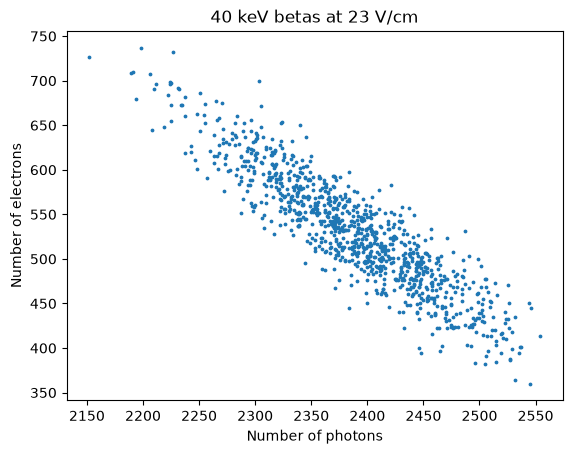

In [12]:
plt.scatter(microphysics_summary["photons"], microphysics_summary["electrons"], s=3)
plt.xlabel("Number of photons")
plt.ylabel("Number of electrons")
plt.title("40 keV betas at 23 V/cm")
plt.show()

In [13]:
number_of_quanta = microphysics_summary["photons"] + microphysics_summary["electrons"]
print("Mean number of quanta:", number_of_quanta.mean())
print("Energy / W:", 40.0 / 13.7e-3)

Mean number of quanta: 2918.284
Energy / W: 2919.70802919708


The positions are uniformly distributed in the TPC, as we wanted:

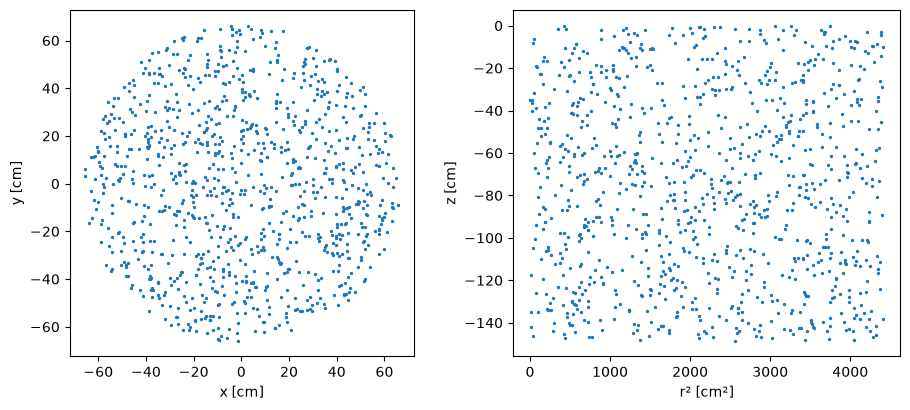

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(microphysics_summary["x"], microphysics_summary["y"], s=2)
axes[0].set_xlabel("x [cm]")
axes[0].set_ylabel("y [cm]")
axes[0].set_aspect("equal")

r_squared = microphysics_summary["x"] ** 2 + microphysics_summary["y"] ** 2
axes[1].scatter(r_squared, microphysics_summary["z"], s=2)
axes[1].set_xlabel("r² [cm²]")
axes[1].set_ylabel("z [cm]")
plt.show()

## 4. Give the number of photons or electrons yourself

Sometimes you do not want NEST to calculate the quanta, for example to test the light simulation with a fixed number of photons. The columns `photons`, `electrons` and `ed` follow these rules:

| `ed` | `photons` / `electrons` | What ember does |
|---|---|---|
| given | both `-1` | NEST calculates photons and electrons |
| given | one or both given | the given numbers are used, NEST calculates only the ones that are `-1` |
| `-1` | at least one given | the given numbers are used, a `-1` becomes 0; the energy is estimated as $W \cdot (N_\gamma + N_e)$ |
| `-1` | both `-1` | error |

The energy estimate is only possible for electronic recoils (betas, gammas, ...). For nuclear recoils and ions (`nestid` ≤ 6) the energy is required.

ember also calculates the number of **excitons**, even if you give the photons yourself. Photons from excitons are emitted promptly, photons from recombination of electrons and ions are emitted later. The next simulation stage needs this split for the time profile of the S1 signal. If the photons are given, ember uses the mean exciton-to-photon ratio of NEST at the given energy.

Let's try four rows: NEST only, photons only, electrons only, and photons and electrons without energy:

In [15]:
example_instructions = pd.DataFrame()
example_instructions["eventid"] = [0, 1, 2, 3]
example_instructions["t"] = [0, 0, 0, 0]
example_instructions["x"] = [0.0, 10.0, 20.0, 30.0]
example_instructions["y"] = [0.0, 0.0, 0.0, 0.0]
example_instructions["z"] = [-50.0, -50.0, -50.0, -50.0]
example_instructions["ed"] = [40.0, -1, -1, -1]
example_instructions["nestid"] = [8, 8, 8, 8]
example_instructions["A"] = [0, 0, 0, 0]
example_instructions["Z"] = [0, 0, 0, 0]
example_instructions["photons"] = [-1, 1000, -1, 2000]
example_instructions["electrons"] = [-1, -1, 500, 800]

example_instructions.to_csv("examples.csv", index=False)
example_instructions

,eventid,t,x,y,z,ed,nestid,A,Z,photons,electrons
0,0,0,0.0,0.0,-50.0,40.0,8,0,0,-1,-1
1,1,0,10.0,0.0,-50.0,-1.0,8,0,0,1000,-1
2,2,0,20.0,0.0,-50.0,-1.0,8,0,0,-1,500
3,3,0,30.0,0.0,-50.0,-1.0,8,0,0,2000,800


In [16]:
st.set_config({"input_file": "examples.csv"})
example_summary = st.get_df("000002", "microphysics_summary")
example_summary[["eventid", "ed", "ed_is_estimated", "photons", "electrons", "excitons"]]

Source finished!


,eventid,ed,ed_is_estimated,photons,electrons,excitons
0,0,40.000000,False,2421,505,433
1,1,13.700000,True,1000,0,144
2,2,6.850000,True,0,500,0
3,3,38.360001,True,2000,800,370


The column `ed_is_estimated` shows which energies were estimated from the quanta.

If you give an energy below 0.0137 keV (or ember estimates one, e.g. for a single photon), ember shows a warning: for such small energies NEST assumes the time profile of scintillation in **gas**, which would make the S1 signal too slow.

## 5. Events with several interactions

Some events consist of several interactions, for example the decay of Kr83m: a first transition of 32.1 keV is followed by a second one of 9.4 keV, on average after 154 ns. Rows with the same `eventid` keep their time difference `t`. ember only chooses the start time of each event.

There are three ways to choose the start times:

| Settings | Start times |
|---|---|
| `source_rate > 0` (default 1 per second) | random, like a real source |
| `source_rate > 0` and `fixed_event_spacing = True` | exactly `1 / source_rate` apart, events never overlap |
| `source_rate = 0` | no start time: `t` is the absolute time |

Let's write three Kr83m events (NEST id 11) with the two transitions at the same position (for simplicity we do not draw a random decay time, but set the second decay alaways to 154 ns).

In [19]:
kr_instructions = pd.DataFrame()
kr_instructions["eventid"] = [0, 0, 1, 1, 2, 2]
kr_instructions["t"] = [0, 154, 0, 154, 0, 154]
kr_instructions["x"] = [10.0, 10.0, -20.0, -20.0, 5.0, 5.0]
kr_instructions["y"] = [0.0, 0.0, 15.0, 15.0, -30.0, -30.0]
kr_instructions["z"] = [-30.0, -30.0, -80.0, -80.0, -120.0, -120.0]
kr_instructions["ed"] = [32.1, 9.4, 32.1, 9.4, 32.1, 9.4]
kr_instructions["nestid"] = [11, 11, 11, 11, 11, 11]
kr_instructions["A"] = [0, 0, 0, 0, 0, 0]
kr_instructions["Z"] = [0, 0, 0, 0, 0, 0]
kr_instructions["photons"] = [-1, -1, -1, -1, -1, -1]
kr_instructions["electrons"] = [-1, -1, -1, -1, -1, -1]

kr_instructions.to_csv("kr83m.csv", index=False)

Simulate them with a fixed spacing of 10 events per second, i.e. 100 ms between events:

In [18]:
st.set_config({"input_file": "kr83m.csv", "source_rate": 10, "fixed_event_spacing": True})
kr_summary = st.get_df("000003", "microphysics_summary")
kr_summary[["eventid", "t", "time", "ed", "photons", "electrons"]]

Source finished!


,eventid,t,time,ed,photons,electrons
0,0,0,0,32.099998,1911,389
1,0,154,154,9.400000,811,1
2,1,0,100000000,32.099998,1948,408
3,1,154,100000154,9.400000,812,5
4,2,0,200000000,32.099998,1935,383
5,2,154,200000154,9.400000,788,3


The events start 100 ms (= $10^8$ ns) apart, and inside each event the second transition follows 154 ns after the first.

## Summary

* The input of ember is a CSV file with one row per interaction: `eventid, t, x, y, z, ed, nestid, A, Z, photons, electrons`.
* `-1` means "not given": NEST calculates missing quanta, and missing energies of electronic recoils are estimated from the given quanta.
* `ember.ember_context()` simulates the microphysics up to `microphysics_summary`.
* Use a new `run_id` for every new input file.

In the next tutorial we will follow the photons and electrons through the detector.